# Conditional return simulation: personal DFM + H guidance versus rejection

**Two experiments, one model implementation.** First fit the personal factor MLP to simulated Gaussian-factor returns and compare conditional covariance against analytical truth. Then fit the same implementation to observed daily return vectors and compare conditional distributions and generation time. No author U-Net, external model checkout, pretrained checkpoint, or open PR is needed.

Three methods share the **same fitted DFM, portfolio event, time grid, output count, CPU precision, and one-thread timing environment**:

1. **DFM rejection:** unconditional DFM paths, retain terminal returns satisfying the event.
2. **Raw H guidance:** learned-H initial rejection followed by H-guided dynamics; report every output, including violations.
3. **H + terminal rejection:** the same learned-H initialization and guidance, then reject terminal violations until the requested count is reached.

H + terminal rejection is approximate conditional sampling: filtering guarantees the event, but does not correct a wrong H-guided density. Raw H is included to expose this distinction.

Run from the repository root after `python -m pip install -r requirements-comparison.txt`. The default is a modest **demonstration**, not a convergence study. The empirical section downloads one public data archive on its first run; afterward it works offline. All generated data, checkpoints, detailed metrics, seeds, source snapshots and logs stay in a new ignored artifact directory. No outputs are overwritten.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import replace
import os
import uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display
from comparison_experiments import (
    ExperimentConfig, paper_population, gaussian_tail, load_market_returns,
    run_comparison, comparison_figures,
)

MODE = os.environ.get('COMPARISON_MODE', 'demo')
assert MODE in ('demo', 'smoke')
CONFIG = ExperimentConfig.smoke() if MODE == 'smoke' else ExperimentConfig()
# Change these declared budgets before running; evaluation does not tune them.
# Example longer fit: CONFIG = replace(CONFIG, dfm_epochs=10000, h_epochs=100)
RUN = Path('artifacts/comparison') / (
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
RUN.mkdir(parents=True, exist_ok=False)
print('Mode:', MODE, '\nConfiguration:', CONFIG, '\nOutputs:', RUN)


Mode: demo 
Configuration: ExperimentConfig(k=4, dfm_epochs=1000, h_epochs=40, train_paths=4096, validation_paths=1024, steps=128, samples=512, reference_samples=2048, repeats=3, batch_size=128, max_proposals=200000, T=5.0, t0=0.01, seed=20261023) 
Outputs: artifacts/comparison/20261023T100232Z_9315cd63


## 1. Simulated returns with exact conditional covariance

Use the Gaussian recipe in [Chen, Xu, Xu & Zhang, DFM, Section 6 and Appendix D](https://arxiv.org/html/2504.06566v5#A4): $R=\beta F+\varepsilon$, independent Gaussian factors and idiosyncratic noise; factor means are uniform on $(0,0.1)$, factor standard deviations are $1.5$ times those means, loadings are standard normal, and noise standard deviations are uniform on $(0,0.4)$. We use **16 assets, 4 factors and 1,024 observed training vectors**, rather than the paper's 2,048 assets and 16 factors. These are synthetic units, not decimal market returns. The seed fixes the population before fitting. Direct multivariate-normal generation is distributionally equivalent to drawing the Gaussian factors and noise separately.

We extend that unconditional data recipe by conditioning an equal-weight portfolio on its lower 10% population tail: $A=\{w^\top R\le c\}$. This tail experiment is **our extension**, not a claimed reproduction of a conditioning experiment in the DFM paper. Only this declared threshold uses population information; neither the DFM nor H receives true parameters or oracle samples.

For $R\sim N(\mu,\Sigma)$, let $s^2=w^\top\Sigma w$, $a=(c-w^\top\mu)/s$, and $\lambda=\phi(a)/\Phi(a)$. Then

$$\mu_A=\mu-\frac{\Sigma w}{s}\lambda,\qquad
\Sigma_A=\Sigma-\frac{\Sigma ww^\top\Sigma}{s^2}\lambda(a+\lambda).$$

The conditioned law is a truncated multivariate Gaussian, not an ordinary Gaussian. Oracle draws use its exact portfolio/residual decomposition. They are evaluation-only.

Two distinct targets are essential: **true population conditional** measures total error (including DFM learning); **fitted DFM conditional** uses a separate larger rejection sample to measure guidance fidelity to the numerical DFM. The latter has Monte Carlo error and includes finite horizon, early stopping and Euler discretization. Neither target certifies convergence.

In [2]:
D, K, N_TRAIN = 16, 4, 1024
TAIL_PROBABILITY = 0.10
mu, Sigma = paper_population(D, K, seed=617)
w = np.full(D, 1 / D)
c = float(w @ mu + np.sqrt(w @ Sigma @ w) * norm.ppf(TAIL_PROBABILITY))
training = np.random.default_rng(618).multivariate_normal(mu, Sigma, size=N_TRAIN)
true_mean, true_covariance = gaussian_tail(mu, Sigma, w, c)
print('Synthetic event: equal-weight return <=', c)
display(pd.DataFrame(true_covariance).round(5))


Synthetic event: equal-weight return <= -0.07546637946413268


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.02978,-0.01144,0.00918,-0.02059,0.00469,-0.00474,0.00611,0.02111,0.03002,-0.00079,-0.01555,0.00407,-0.02947,0.00063,0.02744,-0.05105
1,-0.01144,0.01080,0.01524,0.01012,-0.00765,-0.00276,-0.00004,-0.02191,-0.00136,-0.00284,0.01256,0.01067,0.00825,-0.01143,-0.02133,0.01986
2,0.00918,0.01524,0.11559,0.00118,-0.02687,-0.02279,0.01287,-0.04746,0.07485,-0.00822,0.01798,0.05487,-0.03800,-0.05621,-0.02873,-0.04469
3,-0.02059,0.01012,0.00118,0.11807,-0.03747,0.00577,-0.01634,-0.04831,-0.01264,0.02426,0.01413,-0.02142,0.02619,-0.02263,-0.04183,0.03938
4,0.00469,-0.00765,-0.02687,-0.03747,0.10931,-0.00031,0.00523,-0.00052,-0.02053,-0.01194,-0.01998,-0.00246,-0.01196,0.02050,0.02126,-0.00170
5,-0.00474,-0.00276,-0.02279,0.00577,-0.00031,0.02232,-0.00553,0.00081,-0.02170,0.00562,-0.00217,-0.01573,0.01297,0.00888,-0.00046,0.01827
6,0.00611,-0.00004,0.01287,-0.01634,0.00523,-0.00553,0.00848,0.00147,0.01109,-0.01058,-0.00204,0.01635,-0.01366,-0.00144,0.00661,-0.01422
7,0.02111,-0.02191,-0.04746,-0.04831,-0.00052,0.00081,0.00147,0.17292,-0.00347,0.00145,-0.04465,-0.02988,-0.03029,0.03493,0.05458,-0.04690
8,0.03002,-0.00136,0.07485,-0.01264,-0.02053,-0.02170,0.01109,-0.00347,0.11648,0.00302,-0.00769,0.02957,-0.05915,-0.03819,0.01224,-0.09825
9,-0.00079,-0.00284,-0.00822,0.02426,-0.01194,0.00562,-0.01058,0.00145,0.00302,0.02050,-0.00053,-0.02397,0.00870,-0.00441,-0.00438,-0.00203


In [3]:
synthetic_report, synthetic_arrays = run_comparison(
    training, w, c, RUN / 'synthetic', replace(CONFIG, k=K),
    population=(mu, Sigma), provenance={
        'population_recipe': 'DFM Appendix D, reduced dimensions',
        'population_seed': 617, 'training_seed': 618, 'tail_probability': TAIL_PROBABILITY,
        'units': 'synthetic return units',
    })
print('Status:', synthetic_report['status'])
print('Unconditional DFM error:', synthetic_report['unconditional_fit'])
print('Empirical training error:', synthetic_report['empirical_training_fit'])
print('Exact-oracle sampling-noise baseline:', synthetic_report['oracle_sampling_error'])
print('H validation:', synthetic_report['h']['h_validation'])


synthetic: DFM fitted; generating H labels and fitting H


synthetic: H fitted; benchmarking equal-count draws


Status: complete
Unconditional DFM error: {'covariance_relative_error': 0.2710713723224338, 'mean_rmse': 0.021705489205670465, 'correlation_rmse': 0.11729823522963814}
Empirical training error: {'covariance_relative_error': 0.0863549271599291, 'mean_rmse': 0.011561617820900023, 'correlation_rmse': 0.029854181541490513}
Exact-oracle sampling-noise baseline: {'covariance_relative_error': 0.10517021763217814, 'mean_rmse': 0.006810958158307968, 'correlation_rmse': 0.04302294573946163}
H validation: {'h_loss': 0.09548063948750496, 'constant_loss': 0.10273224115371704, 'event_rate': 0.1162109375}


seconds          event_rate  \
                                              mean      std       mean   
target                      method                                       
fitted_dfm_conditional      dfm_rejection  0.84032  0.05194    1.00000   
                            h_filtered     0.96473  0.05717    1.00000   
                            h_raw          0.40224  0.00691    0.47266   
true_population_conditional dfm_rejection  0.84032  0.05194    1.00000   
                            h_filtered     0.96473  0.05717    1.00000   
                            h_raw          0.40224  0.00691    0.47266   

                                                   covariance_relative_error  \
                                               std                      mean   
target                      method                                             
fitted_dfm_conditional      dfm_rejection  0.00000                   0.10936   
                            h_filtered     0.00000                   0.15175   
                            h_raw          0.02252                   0.17681   
true_population_conditional dfm_rejection  0.00000                   0.30323   
                            h_filtered     0.00000                   0.33293   
                            h_raw          0.02252                   0.33335   

                                                   correlation_rmse           \
                                               std             mean      std   
target                      method                                             
fitted_dfm_conditional      dfm_rejection  0.00719          0.04004  0.00564   
                            h_filtered     0.03088          0.05568  0.00956   
                            h_raw          0.02146          0.05889  0.00701   
true_population_conditional dfm_rejection  0.02045          0.13063  0.00184   
                            h_filtered     0.00327          0.14182  0.00257   
                            h_raw          0.00507          0.14227  0.00305   

                                          mean_rmse           \
                                               mean      std   
target                      method                             
fitted_dfm_conditional      dfm_rejection   0.01053  0.00233   
                            h_filtered      0.05196  0.00287   
                            h_raw           0.05832  0.00093   
true_population_conditional dfm_rejection   0.04583  0.00503   
                            h_filtered      0.07317  0.00161   
                            h_raw           0.08410  0.00097   

                                          portfolio_ks_statistic           \
                                                            mean      std   
target                      method                                          
fitted_dfm_conditional      dfm_rejection                0.03109  0.00923   
                            h_filtered                   0.17155  0.02703   
                            h_raw                        0.52783  0.02196   
true_population_conditional dfm_rejection                0.07129  0.01685   
                            h_filtered                   0.21126  0.03098   
                            h_raw                        0.52751  0.02233   

                                          sliced_wasserstein           
                                                        mean      std  
target                      method                                     
fitted_dfm_conditional      dfm_rejection            0.01463  0.00231  
                            h_filtered               0.03725  0.00287  
                            h_raw                    0.05281  0.00299  
true_population_conditional dfm_rejection            0.04013  0.00327  
                            h_filtered               0.05552  0.00135  
                            h_raw                    0.07308  0.00341

Failures: []


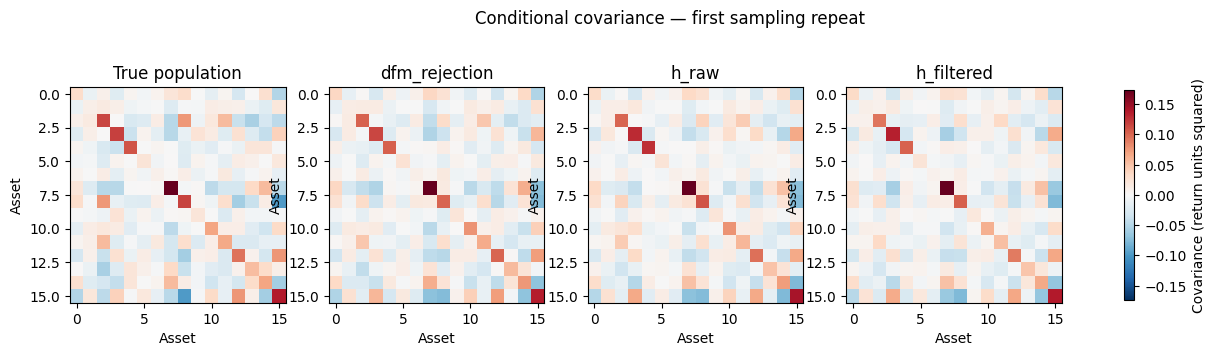

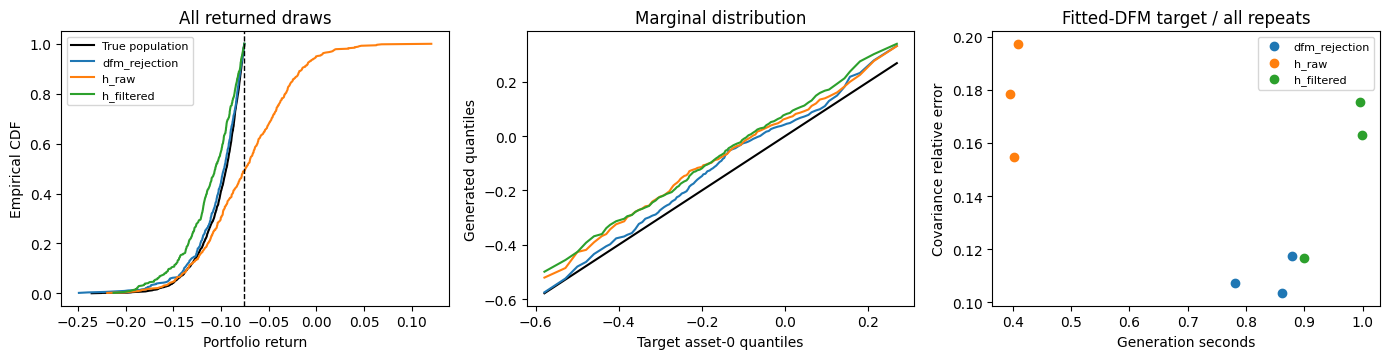

In [4]:
METRICS = ['seconds', 'event_rate', 'covariance_relative_error', 'correlation_rmse',
           'mean_rmse', 'portfolio_ks_statistic', 'sliced_wasserstein']
def result_table(report):
    rows = pd.DataFrame(report['rows'])
    display(rows.groupby(['target', 'method'])[METRICS].agg(['mean', 'std']).round(5))
    print('Failures:', report['failures'])
    return rows
synthetic_rows = result_table(synthetic_report)
for number, figure in enumerate(comparison_figures(synthetic_report, synthetic_arrays)):
    figure.savefig(RUN / 'synthetic' / f'comparison_{number}.png', dpi=150, bbox_inches='tight')
plt.show()


## 2. Fit to observed return series

The default data are the **ten value-weighted daily industry portfolios** from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). This is an observed-return demonstration, not a reproduction of the paper's stock-universe experiment. The archive's returns are in percent and are converted to decimals; missing-value sentinels are removed by complete-case row deletion, with the count recorded. The downloaded snapshot and its SHA-256 identify the input because historical data may be revised.

Training is fixed to **2010–2019**; held-out comparison is **2020–2024**. The equal-weight threshold is the training portfolio's empirical 10% quantile. Per-asset mean and standard deviation are fitted only on training observations and reused for inverse transformation and the event. The DFM learns the cross-sectional distribution of daily vectors, not temporal dependence or multi-day paths.

For real returns, the true conditional covariance is unknown. A fresh larger rejection sample estimates the *fitted DFM's* conditional law. Historical held-out tail observations are a separate descriptive comparison; serial dependence, distribution shifts and limited tail observations prevent treating their covariance as exact truth.

To use your own data, set `RETURN_CSV` below (or the environment variable `COMPARISON_RETURN_CSV`) to a CSV with a `date` first column and one decimal daily simple-return column per asset. Keep the stated date windows or edit the loader explicitly. A missing or malformed dataset raises an error; no simulated data are substituted.

In [5]:
RETURN_CSV = os.environ.get('COMPARISON_RETURN_CSV') or None
market_train, market_test, market_source = load_market_returns(
    Path('data/raw/10_Industry_Portfolios_daily_CSV.zip'), csv_path=RETURN_CSV)
display(pd.Series(market_source, name='Data provenance'))
market_weights = np.full(market_train.shape[1], 1 / market_train.shape[1])
market_threshold = float(np.quantile(market_train.to_numpy() @ market_weights, TAIL_PROBABILITY))
print('Market event: equal-weight daily return <=', market_threshold)
display(market_train.head())


source          https://mba.tuck.dartmouth.edu/pages/faculty/k...
sha256          12e33cce09517c9a2bb38cf75d43b5a15e65238848e864...
units                                decimal daily simple returns
dropped_rows                                                    0
train_rows                                                   2516
test_rows                                                    1258
assets          [NoDur, Durbl, Manuf, Enrgy, HiTec, Telcm, Sho...
train_dates                              [2010-01-04, 2019-12-31]
test_dates                               [2020-01-02, 2024-12-31]
Name: Data provenance, dtype: object

Market event: equal-weight daily return <= -0.009685


,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
2010-01-04,0.0098,0.0235,0.0224,0.0300,0.0159,0.0147,0.0080,0.0131,0.0066,0.0198
2010-01-05,0.0031,0.0257,0.0041,0.0078,0.0000,0.0011,-0.0013,-0.0060,-0.0084,0.0091
2010-01-06,0.0022,0.0123,0.0055,0.0094,-0.0069,-0.0103,-0.0003,0.0053,0.0054,0.0022
2010-01-07,0.0004,0.0144,0.0031,-0.0033,-0.0035,-0.0017,0.0063,0.0013,-0.0045,0.0168
2010-01-08,-0.0048,0.0055,0.0073,0.0045,0.0076,-0.0015,-0.0001,0.0025,-0.0005,0.0029


market: DFM fitted; generating H labels and fitting H


market: H fitted; benchmarking equal-count draws


Status: complete
Held-out event observations: 182
Held-out event frequency: 0.14467408585055644
Unconditional DFM versus held-out moments (descriptive): {'covariance_relative_error': 0.5309849520900896, 'mean_rmse': 0.000864557488544055, 'correlation_rmse': 0.13903191299260703}
H validation: {'h_loss': 0.08462591469287872, 'constant_loss': 0.11518055200576782, 'event_rate': 0.1328125}


seconds           \
                                                      mean      std   
target                              method                            
fitted_dfm_conditional              dfm_rejection  0.79794  0.05605   
                                    h_filtered     0.58327  0.00159   
                                    h_raw          0.38744  0.00323   
historical_heldout_tail_descriptive dfm_rejection  0.79794  0.05605   
                                    h_filtered     0.58327  0.00159   
                                    h_raw          0.38744  0.00323   

                                                  event_rate          \
                                                        mean     std   
target                              method                             
fitted_dfm_conditional              dfm_rejection    1.00000  0.0000   
                                    h_filtered       1.00000  0.0000   
                                    h_raw            0.74219  0.0293   
historical_heldout_tail_descriptive dfm_rejection    1.00000  0.0000   
                                    h_filtered       1.00000  0.0000   
                                    h_raw            0.74219  0.0293   

                                                  covariance_relative_error  \
                                                                       mean   
target                              method                                    
fitted_dfm_conditional              dfm_rejection                   0.11268   
                                    h_filtered                      0.39264   
                                    h_raw                           1.40698   
historical_heldout_tail_descriptive dfm_rejection                   0.74981   
                                    h_filtered                      0.66141   
                                    h_raw                           0.45121   

                                                           correlation_rmse  \
                                                       std             mean   
target                              method                                    
fitted_dfm_conditional              dfm_rejection  0.00942          0.03487   
                                    h_filtered     0.14871          0.08204   
                                    h_raw          0.02230          0.18588   
historical_heldout_tail_descriptive dfm_rejection  0.02636          0.16637   
                                    h_filtered     0.03290          0.15660   
                                    h_raw          0.00585          0.19977   

                                                           mean_rmse           \
                                                       std      mean      std   
target                              method                                      
fitted_dfm_conditional              dfm_rejection  0.00507   0.00051  0.00023   
                                    h_filtered     0.01652   0.00441  0.00044   
                                    h_raw          0.01158   0.00077  0.00015   
historical_heldout_tail_descriptive dfm_rejection  0.01498   0.00357  0.00019   
                                    h_filtered     0.00891   0.00391  0.00039   
                                    h_raw          0.00642   0.00375  0.00036   

                                                  portfolio_ks_statistic  \
                                                                    mean   
target                              method                                 
fitted_dfm_conditional              dfm_rejection                0.03890   
                                    h_filtered                   0.25765   
                                    h_raw                        0.25781   
historical_heldout_tail_descriptive dfm_rejection                0.08887   
                                    h_filtered                   0.29836   


Failures: []


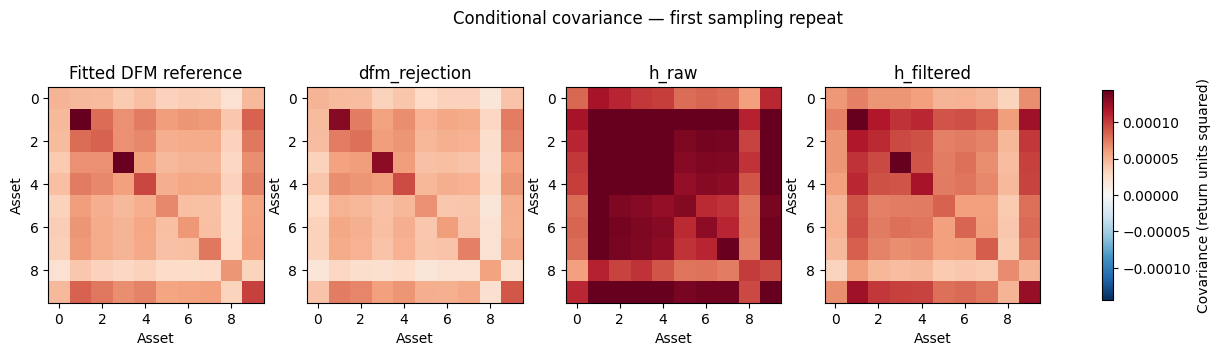

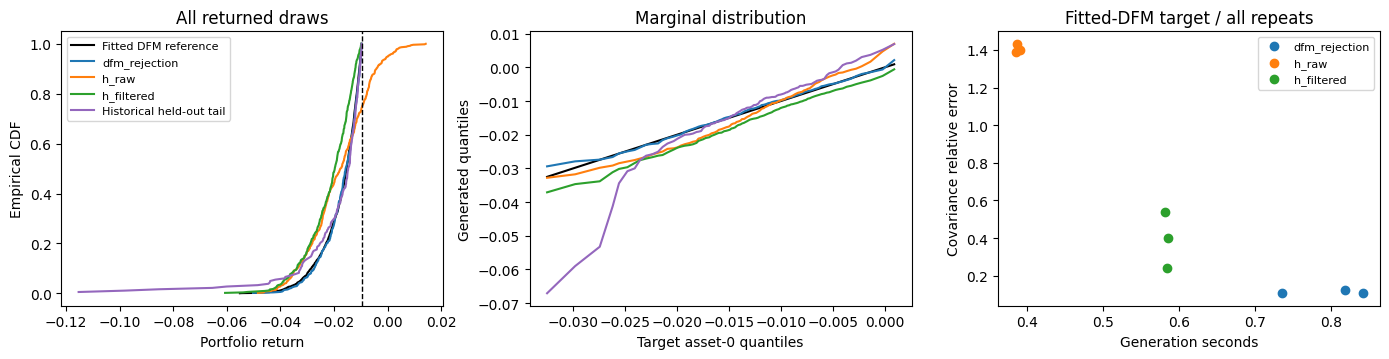

In [6]:
market_report, market_arrays = run_comparison(
    market_train.to_numpy(), market_weights, market_threshold, RUN / 'market',
    replace(CONFIG, k=3, seed=CONFIG.seed + 10000), assets=list(market_train.columns),
    heldout=market_test.to_numpy(), provenance=market_source)
print('Status:', market_report['status'])
print('Held-out event observations:', market_report['heldout_event_count'])
print('Held-out event frequency:', market_report['heldout_event_rate'])
print('Unconditional DFM versus held-out moments (descriptive):', market_report['unconditional_fit'])
print('H validation:', market_report['h']['h_validation'])
market_rows = result_table(market_report)
for number, figure in enumerate(comparison_figures(market_report, market_arrays)):
    figure.savefig(RUN / 'market' / f'comparison_{number}.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Cost and interpretation

Generation time includes learned-H initial rejection, integration, terminal rejection and discarded overshoot. Both methods return the same number of samples. Warm-up, independent-reference generation, plotting and metric computation are excluded. Method order rotates across repeats and each method/repeat has a separate fixed seed. Every repeat reuses the same fitted DFM/H; the reported standard deviation describes sampling/timing variation, **not uncertainty across model fits**.

DFM training is common to all methods. H adds label-generation, training and validation costs; the table below includes those in total cost for an actual equal-sized batch. This is distinct from steady-state generation speed. Proposal budgets are finite and failures are recorded; incomplete batches are never reported as successes.

A faster method is useful only if its error is acceptable for the application. Event rate near one, small covariance error, or one marginal match alone does not establish joint-distribution accuracy. H probability-validation loss does not validate guidance gradients. Do not claim superiority from this one fit or select settings against the final references.

In [7]:
def cost_table(report):
    rows = pd.DataFrame(report['rows'])
    timing = rows[rows.target == 'fitted_dfm_conditional'].groupby('method').seconds.agg(['mean', 'std'])
    timing.columns = ['generation_mean_seconds', 'generation_sd_seconds']
    timing['dfm_training_seconds_common'] = report['costs']['dfm_training_seconds']
    timing['h_setup_seconds'] = [0.0 if m == 'dfm_rejection' else
        report['costs']['h_setup_including_validation_seconds'] for m in timing.index]
    timing['first_batch_total_seconds'] = (timing.generation_mean_seconds +
        timing.dfm_training_seconds_common + timing.h_setup_seconds)
    if 'dfm_rejection' in timing.index:
        timing['generation_speedup_vs_rejection'] = (
            timing.loc['dfm_rejection', 'generation_mean_seconds'] / timing.generation_mean_seconds)
    return timing
print('Synthetic cost:')
display(cost_table(synthetic_report).round(3))
print('Observed-return cost:')
display(cost_table(market_report).round(3))
print('Full results and covariance/sample arrays:', RUN.resolve())


Synthetic cost:


,generation_mean_seconds,generation_sd_seconds,dfm_training_seconds_common,h_setup_seconds,first_batch_total_seconds,generation_speedup_vs_rejection
method,,,,,,
dfm_rejection,0.840,0.052,7.957,0.000,8.797,1.000
h_filtered,0.965,0.057,7.957,20.088,29.009,0.871
h_raw,0.402,0.007,7.957,20.088,28.447,2.089


Observed-return cost:


,generation_mean_seconds,generation_sd_seconds,dfm_training_seconds_common,h_setup_seconds,first_batch_total_seconds,generation_speedup_vs_rejection
method,,,,,,
dfm_rejection,0.798,0.056,17.601,0.000,18.399,1.000
h_filtered,0.583,0.002,17.601,18.359,36.544,1.368
h_raw,0.387,0.003,17.601,18.359,36.348,2.060


Full results and covariance/sample arrays: /private/tmp/master-thesis-focused-20261023/artifacts/comparison/20261023T100232Z_9315cd63


## What this notebook establishes, and what remains

This notebook makes the requested experiments executable using the personal implementation already on `main`. It saves the true conditional covariance for the synthetic problem and estimates both conditional samplers' covariance in original return units. It also compares distribution diagnostics and costs after fitting to observed returns.

The displayed run is a reproducible demonstration, not a validated research conclusion. Before reporting comparative scientific performance, repeat complete fits with prespecified seeds, inspect unconditional DFM quality, increase training and H supervision as needed, and check integration-grid/early-stopping sensitivity. Refit H whenever its reference or grid changes. Use new independent evaluation draws after exploratory tuning.

The paper's full dimensions and U-Net are unnecessary for this scoped comparison. The pending author-backend PRs are not dependencies. Large local historical artifacts and unrelated notebooks are not needed to run this one.